In [434]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.ensemble import RandomForestClassifier 
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks
from imblearn.pipeline import Pipeline as imbpipeline
from imblearn.under_sampling import RandomUnderSampler

In [435]:
df=pd.read_csv('emp_att.csv')
df.head().T

,0,1,2,3,4
Age,41,49,37,33,27
Attrition,Yes,No,Yes,No,No
BusinessTravel,Travel_Rarely,Travel_Frequently,Travel_Rarely,Travel_Frequently,Travel_Rarely
DailyRate,1102,279,1373,1392,591
Department,Sales,Research & Development,Research & Development,Research & Development,Research & Development
DistanceFromHome,1,8,2,3,2
Education,2,1,2,4,1
EducationField,Life Sciences,Life Sciences,Other,Life Sciences,Medical
EmployeeCount,1,1,1,1,1
EmployeeNumber,1,2,4,5,7


In [436]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [437]:
df.isnull().sum()

Age                         0Attrition                   0BusinessTravel              0DailyRate                   0Department                  0DistanceFromHome            0Education                   0EducationField              0EmployeeCount               0EmployeeNumber              0EnvironmentSatisfaction     0Gender                      0HourlyRate                  0JobInvolvement              0JobLevel                    0JobRole                     0JobSatisfaction             0MaritalStatus               0MonthlyIncome               0MonthlyRate                 0NumCompaniesWorked          0Over18                      0OverTime                    0PercentSalaryHike           0PerformanceRating           0RelationshipSatisfaction    0StandardHours               0StockOptionLevel            0TotalWorkingYears           0TrainingTimesLastYear       0WorkLifeBalance             0YearsAtCompany              0YearsInCurrentRole          0YearsSinceLastPromotion     0YearsWithCurrM

In [438]:
df['Attrition'].value_counts()

AttritionNo     1233Yes     237Name: count, dtype: int64

In [439]:
df['MaritalStatus'].isnull().sum()

0

In [440]:
df['MaritalStatus'].value_counts()

MaritalStatusMarried     673Single      470Divorced    327Name: count, dtype: int64

In [441]:
df=df.drop(columns=['Over18','EmployeeNumber','EmployeeCount','StandardHours','DailyRate','HourlyRate'])
df.nunique()

Age                           43Attrition                      2BusinessTravel                 3Department                     3DistanceFromHome              29Education                      5EducationField                 6EnvironmentSatisfaction        4Gender                         2JobInvolvement                 4JobLevel                       5JobRole                        9JobSatisfaction                4MaritalStatus                  3MonthlyIncome               1349MonthlyRate                 1427NumCompaniesWorked            10OverTime                       2PercentSalaryHike             15PerformanceRating              2RelationshipSatisfaction       4StockOptionLevel               4TotalWorkingYears             40TrainingTimesLastYear          7WorkLifeBalance                4YearsAtCompany                37YearsInCurrentRole            19YearsSinceLastPromotion       16YearsWithCurrManager          18dtype: int64

In [442]:
df['income_age_ratio']=df['MonthlyIncome']/df['Age']
df['Stability']=df['YearsAtCompany']/(df['NumCompaniesWorked']+1)
df['Stagnation']=df['YearsSinceLastPromotion']/(df['YearsAtCompany']+1)

In [443]:
df['Attrition']=df['Attrition'].map({'Yes':1,'No':0})
df['OverTime']=df['OverTime'].map({'Yes':1,'No':0})
df['Gender']=df['Gender'].map({'Male':1,'Female':0})
df['MaritalStatus']=df['MaritalStatus'].fillna('unknown')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1470 non-null   int64  
 1   Attrition                 1470 non-null   int64  
 2   BusinessTravel            1470 non-null   object 
 3   Department                1470 non-null   object 
 4   DistanceFromHome          1470 non-null   int64  
 5   Education                 1470 non-null   int64  
 6   EducationField            1470 non-null   object 
 7   EnvironmentSatisfaction   1470 non-null   int64  
 8   Gender                    1470 non-null   int64  
 9   JobInvolvement            1470 non-null   int64  
 10  JobLevel                  1470 non-null   int64  
 11  JobRole                   1470 non-null   object 
 12  JobSatisfaction           1470 non-null   int64  
 13  MaritalStatus             1470 non-null   object 
 14  MonthlyI

In [444]:
x=df.drop('Attrition',axis=1)
y=df['Attrition']

In [445]:
cat_cols=x.select_dtypes(include=['object']).columns.tolist()
num_cols=['Age','DistanceFromHome','MonthlyIncome','MonthlyRate','NumCompaniesWorked','PercentSalaryHike','TotalWorkingYears','TrainingTimesLastYear','YearsAtCompany','YearsInCurrentRole','YearsSinceLastPromotion','YearsWithCurrManager']

In [446]:
preprocessor=ColumnTransformer(
    transformers=[
        ('num',StandardScaler(),num_cols),
        ('cat',OneHotEncoder(drop='first',handle_unknown='ignore'),cat_cols)
    ], 
    remainder='passthrough'   
)

In [447]:
pipeline=Pipeline(
    steps=[
        ('preprocessor',preprocessor),
         (
            'classifier',
            RandomForestClassifier(
                n_estimators=350,
                random_state=42,
                max_depth=7,
                min_samples_leaf=5,
                max_features='sqrt',
        ),
        ),
    ]
)

In [448]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [449]:
pipeline.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',                 ColumnTransformer(remainder='passthrough',                                   transformers=[('num', StandardScaler(),                                                  ['Age', 'DistanceFromHome',                                                   'MonthlyIncome',                                                   'MonthlyRate',                                                   'NumCompaniesWorked',                                                   'PercentSalaryHike',                                                   'TotalWorkingYears',                                                   'TrainingTimesLastYear',                                                   'YearsAtCompany',                                                   'YearsInCurrentRole',                                                   'YearsSinceLastPromotion',                                                   'YearsWithCurrManager']),                                                 ('cat',                                                  OneHotEncoder(drop='first',                                                                handle_unknown='ignore'),                                                  ['BusinessTravel',                                                   'Department',                                                   'EducationField', 'JobRole',                                                   'MaritalStatus'])])),                ('classifier',                 RandomForestClassifier(max_depth=7, min_samples_leaf=5,                                        n_estimators=350, random_state=42))])

              precision    recall  f1-score   support

  Stayed (0)       0.93      0.81      0.87       247
    Left (1)       0.41      0.70      0.52        47

    accuracy                           0.79       294
   macro avg       0.67      0.76      0.69       294
weighted avg       0.85      0.79      0.81       294

[[200  47]
 [ 14  33]]


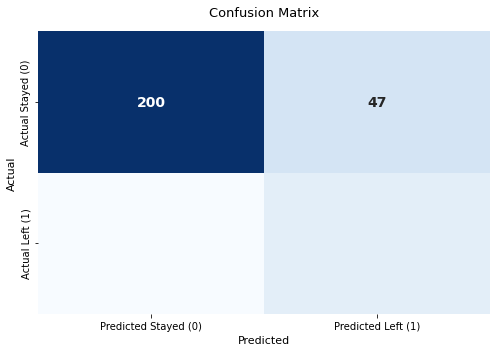

In [450]:
y_pred_train = pipeline.predict(x_train)
y_pred_test = pipeline.predict(x_test)
train_probs = pipeline.predict_proba(x_train)[:, 1]
test_probs = pipeline.predict_proba(x_test)[:, 1]

# 2. SET A CUSTOM THRESHOLD TO MAXIMIZE RECALL
threshold = 0.2

# 3. Convert probabilities to binary outcomes using the threshold
y_pred_train_custom = (train_probs >= threshold).astype(int)
y_pred_test_custom = (test_probs >= threshold).astype(int)

# Evaluate
print(
    classification_report(
        y_test, y_pred_test_custom, target_names=["Stayed (0)", "Left (1)"]
    )
)
cm = confusion_matrix(y_test, y_pred_test_custom)
print(cm)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted Stayed (0)", "Predicted Left (1)"],
    yticklabels=["Actual Stayed (0)", "Actual Left (1)"],
    annot_kws={"size": 14, "weight": "bold"},
)

plt.title("Confusion Matrix", fontsize=13, pad=15)
plt.ylabel("Actual", fontsize=11)
plt.xlabel("Predicted", fontsize=11)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/usr/local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/usr/local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


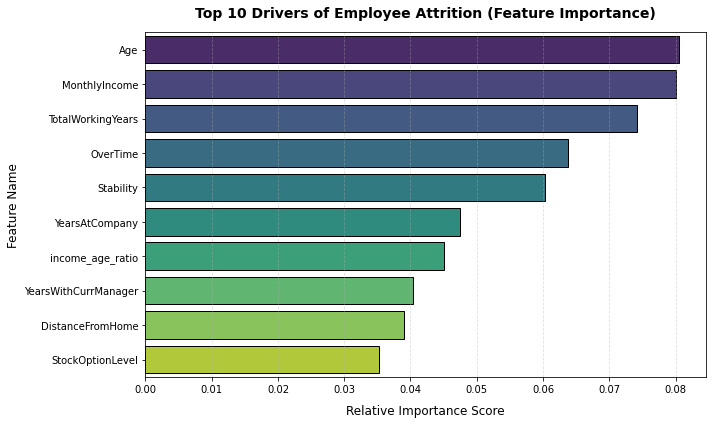

In [451]:
classifier=pipeline.named_steps['classifier']
feature_names=pipeline.named_steps['preprocessor'].get_feature_names_out()
importance_df=pd.DataFrame({'Feature':feature_names,'importance':classifier.feature_importances_}).sort_values(by='importance',ascending=False).reset_index(drop=True)
importance_df['Feature'] = importance_df['Feature'].str.split('__').str[-1]
top_features=importance_df.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_features,
    x="importance",
    y="Feature",
    palette="viridis",
    edgecolor="black",
)
plt.title(
    "Top 10 Drivers of Employee Attrition (Feature Importance)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Relative Importance Score", fontsize=12, labelpad=10)
plt.ylabel("Feature Name", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

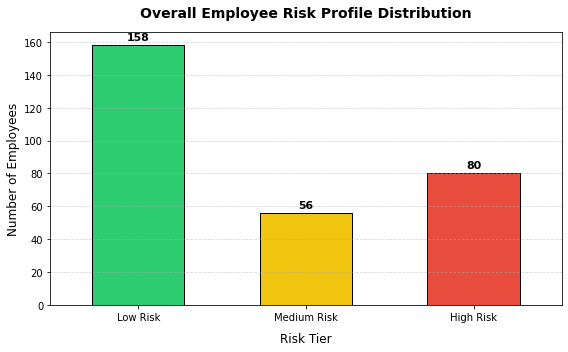

In [452]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# raw probability predictions from pipeline
probabilities = pipeline.predict_proba(x_test)[:, 1]

# Categorize the probabilities using threshold limits
risk_tiers = pd.cut(
    probabilities,
    bins=[-np.inf, 0.13, 0.20, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"],
)
counts = risk_tiers.value_counts().reindex(
    ["Low Risk", "Medium Risk", "High Risk"]
)

# Plot  Bar Chart
plt.figure(figsize=(8, 5))
colors = ["#2ecc71", "#f1c40f", "#e74c3c"]  # Green, Yellow, Red
ax = counts.plot(kind="bar", color=colors, edgecolor="black", width=0.55)
plt.title(
    "Overall Employee Risk Profile Distribution",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Risk Tier", fontsize=12, labelpad=10)
plt.ylabel("Number of Employees", fontsize=12)
plt.xticks(rotation=0) 
plt.grid(axis="y", linestyle="--", alpha=0.5)

# exact headcount labels right on top of each bar
for patch in ax.patches:
    ax.annotate(
        f"{int(patch.get_height())}",
        (patch.get_x() + patch.get_width() / 2.0, patch.get_height()),
        ha="center",
        va="center",
        xytext=(0, 8),
        textcoords="offset points",
        fontweight="bold",
        fontsize=11,
    )

plt.tight_layout()
plt.show()